# Mission 1: Dataset Analysis and Baseline Models

## 1. Project Overview

**Project:** How Long Will the Battery Last?

**Team:** Team 13

**Dataset:** `data/team_13_train.csv`

**Objective:** Analyse the battery sensor dataset, identify data quality issues, understand relationships between input features and battery life, and establish baseline prediction models.

## 2. Dataset Description

The dataset contains five input features and one target variable:

- `battery_v`
- `temp_c`
- `rings_per_day`
- `wifi_rssi_dbm`
- `age_months`
- `days_left`

The target variable is `days_left`, which represents the predicted remaining battery life in days.

In [4]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Team 13 dataset

df = pd.read_csv("data/team_13_train.csv")

# Display first five rows

df.head()

,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
0,3.767,18.2,17,-85,35,19.1
1,4.184,24.3,4,-63,15,221.7
2,3.585,18.7,16,-50,35,14.8
3,3.480,10.0,11,-56,3,10.9
4,3.366,28.7,10,-47,0,2.6


In [5]:
# Descriptive statistical analysis

df.describe()

,battery_v,temp_c,rings_per_day,wifi_rssi_dbm,age_months,days_left
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,3.756825,27.165150,7.938500,-66.298000,18.205000,75.554550
std,0.371475,11.936212,5.631303,12.547108,10.661745,67.287199
min,0.000000,-127.000000,0.000000,-88.000000,0.000000,0.200000
25%,3.560000,22.975000,4.000000,-76.000000,9.000000,19.975000
50%,3.772000,27.900000,7.000000,-66.000000,18.000000,59.450000
75%,3.985250,32.400000,11.000000,-56.000000,27.000000,114.400000
max,4.200000,46.000000,44.000000,0.000000,36.000000,367.200000


## 3. Data Distribution Analysis

Histograms are used to understand the distribution of each dataset feature, identify skewness, observe unusual values, and understand the spread of the data.

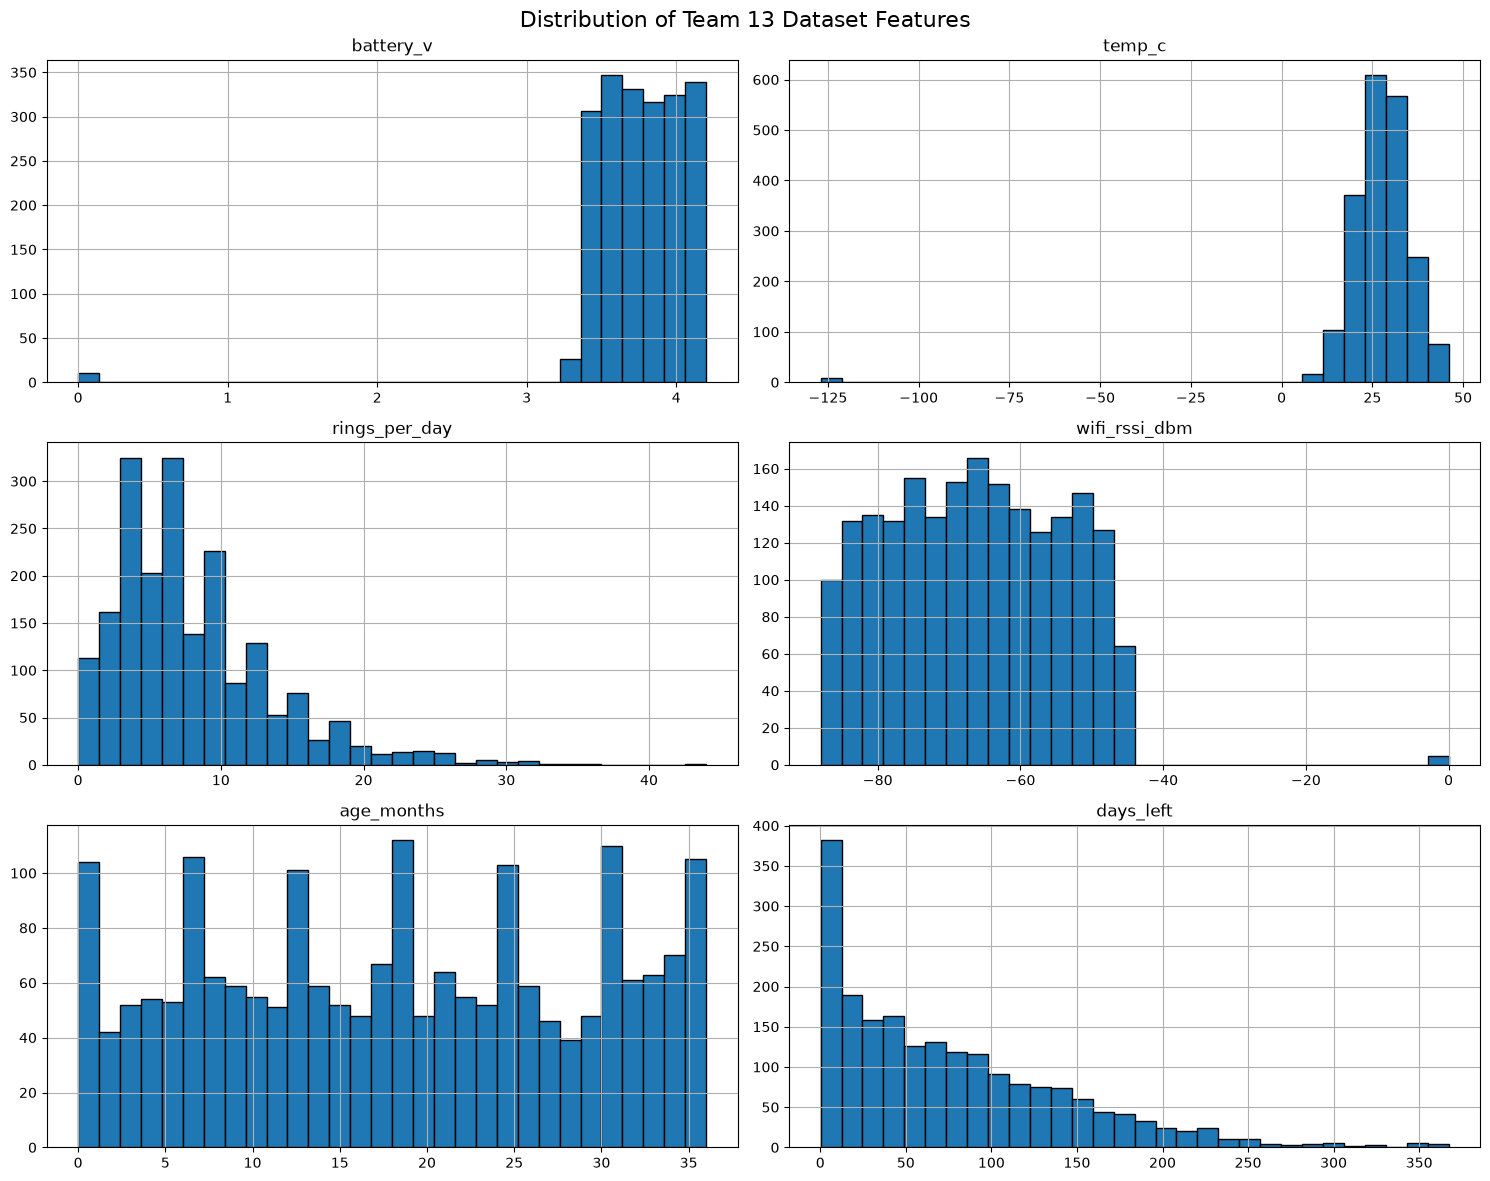

In [6]:
# Plot histograms for all dataset columns

df.hist(figsize=(15, 12), bins=30, edgecolor="black")

plt.suptitle("Distribution of Team 13 Dataset Features", fontsize=16)

plt.tight_layout()
plt.show()

### Histogram Analysis – Observations

1. Battery voltage: Most readings are concentrated between approximately 3.4 V and 4.2 V. A small group of readings occurs at 0 V.

2. Temperature: Most readings fall within a normal-looking range, but an isolated reading at -127°C is observed.

3. Rings per day: The distribution is right-skewed, with most observations at lower ring counts.

4. Wi-Fi RSSI: Most readings are between approximately -88 dBm and -45 dBm. A small group occurs at 0 dBm.

5. Device age: Readings cover the range from 0 to 36 months, with noticeable peaks at certain ages.

6. Days left: The target variable has a right-skewed distribution, with a long tail towards higher remaining battery life.

These observations will be investigated further during sensor glitch detection and feature relationship analysis.

## 4. Feature vs Target Relationship Analysis

In this section, we analyse the relationship between each input feature and the target variable `days_left`.

Scatter plots are used to identify trends, correlations, nonlinear relationships and unusual observations.

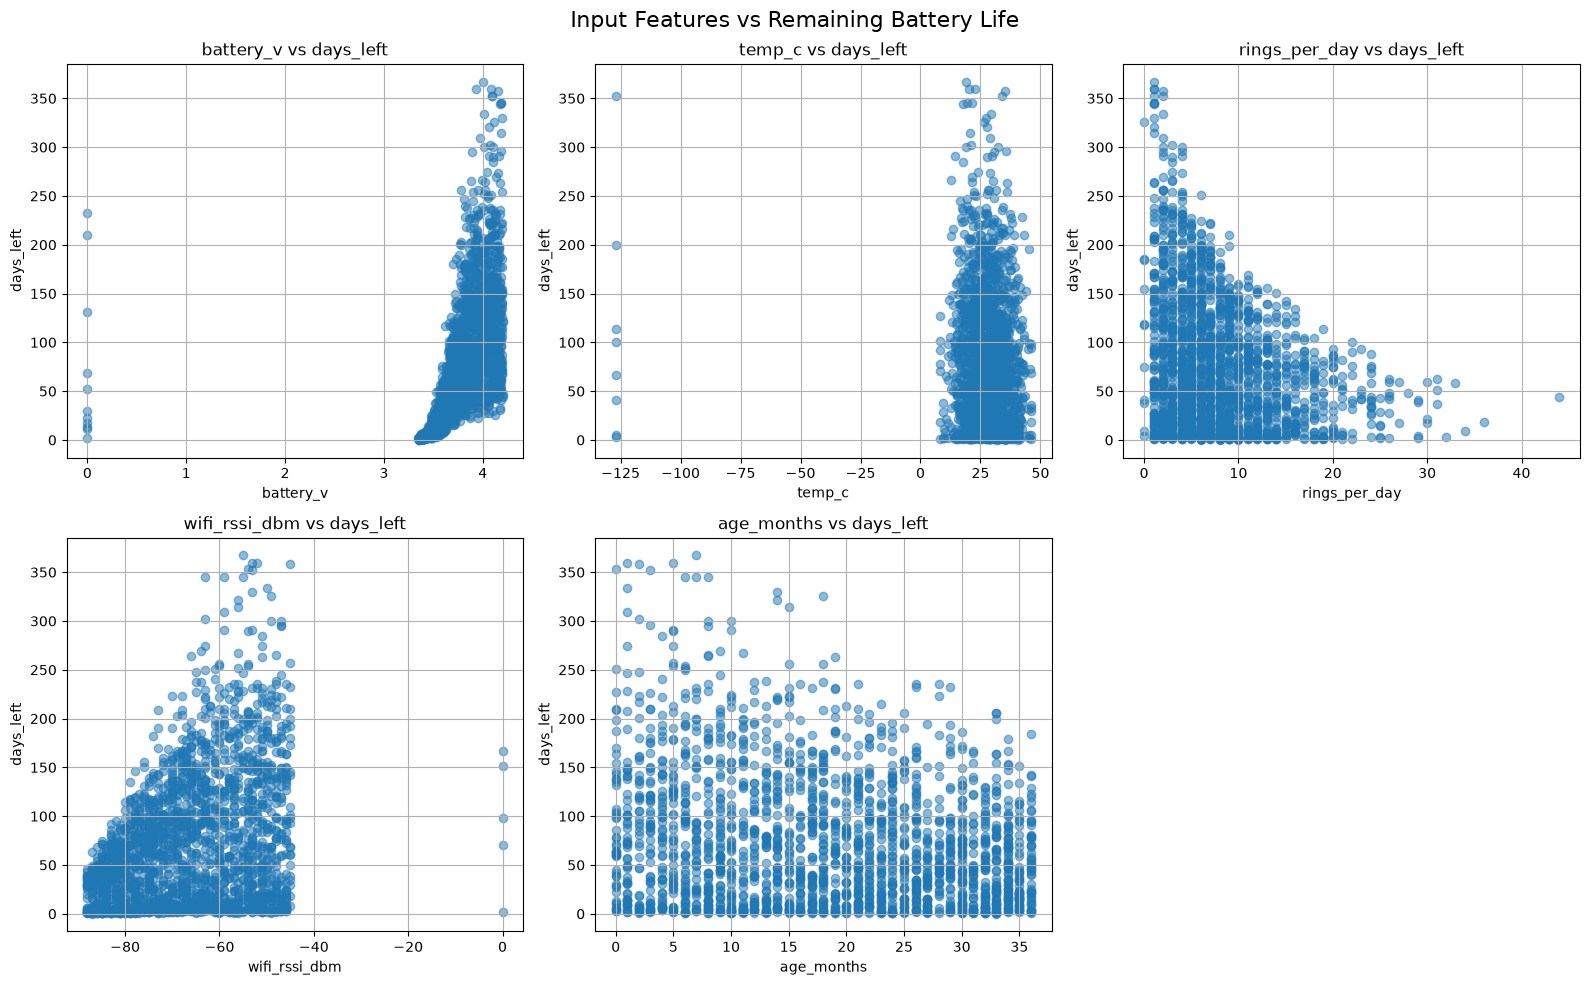

In [7]:
# Scatter plots: Each input feature against days_left

features = [
    "battery_v",
    "temp_c",
    "rings_per_day",
    "wifi_rssi_dbm",
    "age_months"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for i, feature in enumerate(features):
    ax = axes.flat[i]

    ax.scatter(df[feature], df["days_left"], alpha=0.5)
    ax.set_xlabel(feature)
    ax.set_ylabel("days_left")
    ax.set_title(f"{feature} vs days_left")
    ax.grid(True)

# Remove unused sixth plot
fig.delaxes(axes.flat[5])

plt.suptitle("Input Features vs Remaining Battery Life", fontsize=16)
plt.tight_layout()
plt.show()

### Feature vs Target Relationship Analysis

1. Battery Voltage (`battery_v`):
   A positive nonlinear relationship is observed. Higher battery voltage generally corresponds to higher remaining battery life. Several zero-voltage readings appear isolated from the main data distribution.

2. Temperature (`temp_c`):
   No clear strong relationship is visible in the main data cluster. An unusual reading around -127°C is observed and requires investigation.

3. Daily Ring Count (`rings_per_day`):
   A negative nonlinear relationship is observed. Higher daily ring counts generally correspond to lower remaining battery life.

4. Wi-Fi Signal Strength (`wifi_rssi_dbm`):
   A positive association is observed. Stronger Wi-Fi signal readings generally correspond to a higher upper range of remaining battery life. The relationship has considerable variation.

5. Device Age (`age_months`):
   No strong linear relationship is visible. Remaining battery life varies considerably across device ages.

### Overall Observation

Battery voltage, daily ring count and Wi-Fi signal strength show the most noticeable patterns with remaining battery life.

Several relationships appear nonlinear, suggesting that a simple linear model may not fully capture the relationships between the sensor inputs and the target variable.

These observations are based on visual analysis and do not establish causation.

## 5. Correlation Analysis

### Objective

Correlation analysis is used to measure the strength and direction of relationships between the input features and the target variable (`days_left`).

We will use two correlation methods:

1. **Pearson Correlation:** Measures the strength and direction of a linear relationship between two variables.
2. **Spearman Correlation:** Measures the strength and direction of a monotonic relationship using ranked values. It can identify relationships that are not necessarily linear.

### Purpose

- Identify which input features have stronger associations with remaining battery life.
- Compare linear and monotonic relationships.
- Investigate whether temperature has a measurable relationship with battery life.
- Support further feature and model analysis.

Correlation does not establish causation.

In [8]:
# Pearson and Spearman correlation analysis

print("PEARSON CORRELATION")
pearson = df.corr(method="pearson")
print(pearson["days_left"].sort_values(ascending=False))

print("\nSPEARMAN CORRELATION")
spearman = df.corr(method="spearman")
print(spearman["days_left"].sort_values(ascending=False))

PEARSON CORRELATION
days_left        1.000000
battery_v        0.464509
wifi_rssi_dbm    0.344635
temp_c          -0.063449
age_months      -0.220986
rings_per_day   -0.273241
Name: days_left, dtype: float64

SPEARMAN CORRELATION
days_left        1.000000
battery_v        0.799300
wifi_rssi_dbm    0.316930
temp_c          -0.057094
age_months      -0.175657
rings_per_day   -0.226332
Name: days_left, dtype: float64


### Correlation Analysis – Results and Interpretation

Two correlation methods were used to investigate the relationships between the five input features and the target variable `days_left`.

**Pearson correlation results:**
- Battery voltage: +0.4645
- Wi-Fi signal strength: +0.3446
- Temperature: -0.0634
- Device age: -0.2210
- Daily ring count: -0.2732

**Spearman correlation results:**
- Battery voltage: +0.7993
- Wi-Fi signal strength: +0.3169
- Temperature: -0.0571
- Device age: -0.1757
- Daily ring count: -0.2263

**Key observations:**

1. Battery voltage has the strongest positive association with remaining battery life. Its higher Spearman value suggests a strong monotonic relationship that may not be linear.
2. Wi-Fi signal strength shows a moderate positive association.
3. Daily ring count shows a negative association with remaining battery life.
4. Device age shows a weak negative association.
5. Temperature has a very weak overall correlation using both methods. However, possible interactions with other features require further investigation.

**Conclusion:**

The correlation results support the preliminary visual analysis. Battery voltage, Wi-Fi signal strength and daily ring count show more noticeable associations with the target.

All five input features will be retained for further investigation. Correlation alone is not sufficient to determine whether a feature should be removed.

## 6. Feature Interaction Analysis

### Objective

Individual feature analysis does not reveal every relationship between sensor readings and remaining battery life.

In this section, we investigate possible interactions between input features.

Special attention is given to temperature and battery voltage to determine whether temperature has a different relationship with remaining battery life at different voltage levels.

The objective is to identify patterns that may not be visible through individual scatter plots or simple correlation analysis.

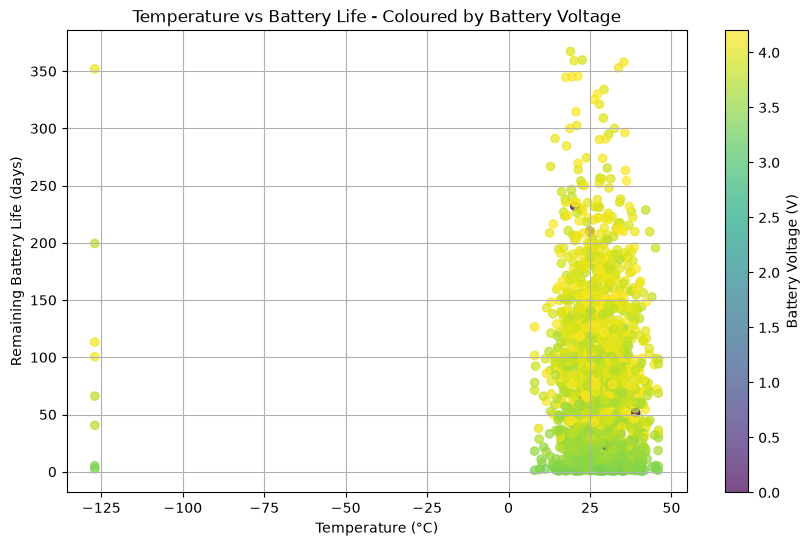

In [9]:
# Temperature and battery voltage interaction analysis

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    df["temp_c"],
    df["days_left"],
    c=df["battery_v"],
    cmap="viridis",
    alpha=0.7
)

plt.colorbar(scatter, label="Battery Voltage (V)")

plt.xlabel("Temperature (°C)")
plt.ylabel("Remaining Battery Life (days)")
plt.title("Temperature vs Battery Life - Coloured by Battery Voltage")

plt.grid(True)
plt.show()

### Feature Interaction Analysis – Temperature and Battery Voltage

A scatter plot was generated between temperature and remaining battery life, with battery voltage represented through colour intensity.

**Observations:**

1. Most temperature readings are concentrated between approximately 10°C and 46°C.
2. Most battery voltage readings are concentrated between approximately 3.5 V and 4.2 V.
3. Remaining battery life shows considerable variation even at similar temperature and battery voltage levels.
4. No clear independent temperature-dependent pattern can be established from this visualization alone.
5. Readings around -127°C are isolated and require physical glitch investigation.

**Conclusion:**

The interaction plot provides an initial view of temperature and battery voltage together. However, further statistical and predictive experiments are required to determine the contribution of temperature.

All five input features will be retained for subsequent model experiments.

### Temperature Analysis Across Battery Voltage Groups

The dataset is divided into battery-voltage groups to investigate whether the relationship between temperature and remaining battery life changes across different voltage levels.

This analysis helps identify possible feature interactions that may not be visible in an overall scatter plot.